# An anisotropic field

Many fields stretch along a direction. Sediments settle in layers, pollution drifts with the wind, and
ore follows faults, so values stay alike over a longer distance one way than the other. Kriging handles
this through an anisotropic variogram, with a direction and two ranges that someone must supply. The
ensemble is told nothing. Here we compare the two on a simulated field whose anisotropy we can measure
exactly, kriging given the true variogram, kriging given the variogram a practitioner would fit, and two
decoders of the ensemble.

## Learning goals

- How to measure the anisotropy of a field, and how to see it in a map.
- How close the ensemble comes to kriging with the true anisotropic variogram, without being told it.
- What a variogram fitted to the data in the usual way gives, against the true one.
- How the density of the data limits what any method learns about the direction.

*Can an ensemble follow a direction no one gives it?*

## The idea

A **geometric anisotropy** stretches the correlation along one direction. The variogram rises more slowly
along it, reaching the sill at a longer range, and faster across it. Kriging needs the direction and both
ranges. Fitted from a few hundred data, they are hard to get right, so practice often settles for an
isotropic variogram.

The ensemble takes a different route. Its **adaptive IDW** decoder fits, in every cell, an exponent and an
anisotropy of its own from the data of that cell, so each partition follows the local direction, the average over the partitions following it everywhere. Spatialize's **kriging decoder**, ordinary kriging
inside each cell, takes an isotropic variogram, so it gets no direction from its model, only from the
data near each location.

## Step by step

### The field

The data set bundles 100 Gaussian simulations of the same anisotropic field on a 200 × 200 grid, with
400 of its nodes (1 %) as samples. We work on the first realisation and use all 100 to measure the
variogram.

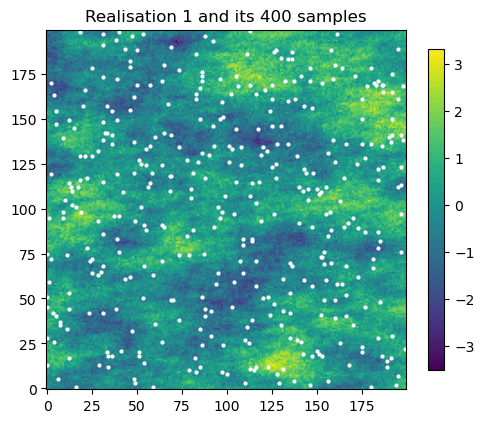

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, sobel
from scipy.optimize import curve_fit, least_squares
from pykrige.ok import OrdinaryKriging

import spatialize
from spatialize.data import load_simulated_anisotropic_data
from spatialize.gs.esi import esi_nongriddata, esi_pareto_hparams_search
import spatialize.gs.esi.scoring as sc

spatialize.session.set(empty_cells="coarsen", progress=False)
warnings.filterwarnings("ignore", module="pykrige")

sample_1pct, sample_5pct, _, ground_truth = load_simulated_anisotropic_data()
xi = ground_truth[["x", "y"]].values
points = sample_1pct[0][["x", "y"]].values
realisations = [f"sim{i}" for i in range(1, 101)]
fields = ground_truth[realisations].values.reshape(200, 200, 100)   # the grid runs along x first: [y, x, realisation]

fig, ax = plt.subplots(figsize=(5.8, 5.2))
im = ax.imshow(fields[..., 0], origin="lower", cmap="viridis")
ax.scatter(points[:, 0], points[:, 1], s=4, c="white")
ax.set_title("Realisation 1 and its 400 samples")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

The patches stretch along the x axis. The samples lie some 10 cells apart, a third of the shortest
correlation length, as the variogram shows.

### The variogram, measured exactly

With 100 complete realisations the variogram needs no fitting from scattered data. Half the mean squared
difference between the grid and itself shifted by a lag, over all 100 realisations, gives it along any
direction. A spherical model with a nugget, fitted to the curves along x and along y together, then
gives the true variogram.

nugget 0.10, partial sill 0.94, range 72 along x and 37 along y


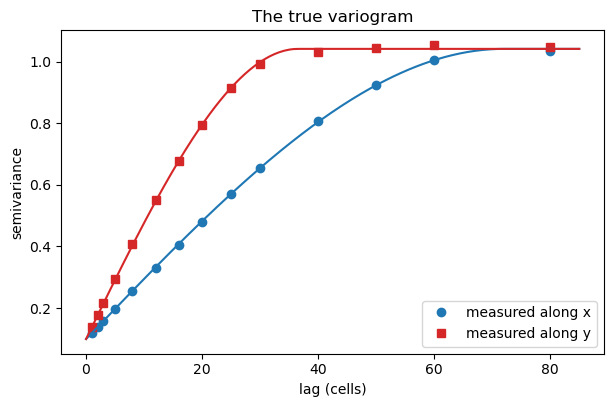

In [2]:
lags = np.array([1, 2, 3, 5, 8, 12, 16, 20, 25, 30, 40, 50, 60, 80])

def gamma(dy, dx):
    a = fields[max(0, -dy):200 - max(0, dy), max(0, -dx):200 - max(0, dx)]
    b = fields[max(0, dy):200 + min(0, dy), max(0, dx):200 + min(0, dx)]
    return 0.5 * np.mean((a - b) ** 2)

along_x = np.array([gamma(0, h) for h in lags])
along_y = np.array([gamma(h, 0) for h in lags])

def spherical(h, a):
    return np.where(h < a, 1.5 * h / a - 0.5 * (h / a) ** 3, 1.0)

fit = least_squares(lambda p: np.r_[p[0] + p[1] * spherical(lags, p[2]) - along_x,
                                    p[0] + p[1] * spherical(lags, p[3]) - along_y],
                    [0.1, 0.9, 60, 30], bounds=([0, 0.1, 1, 1], [1, 3, 500, 500]))
nugget, partial_sill, range_x, range_y = fit.x
print(f"nugget {nugget:.2f}, partial sill {partial_sill:.2f}, range {range_x:.0f} along x and {range_y:.0f} along y")

h = np.linspace(0, 85, 200)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(lags, along_x, "o", color="C0", label="measured along x")
ax.plot(lags, along_y, "s", color="C3", label="measured along y")
ax.plot(h, nugget + partial_sill * spherical(h, range_x), color="C0")
ax.plot(h, nugget + partial_sill * spherical(h, range_y), color="C3")
ax.set_xlabel("lag (cells)"); ax.set_ylabel("semivariance")
ax.set_title("The true variogram")
ax.legend()
plt.show()

The variogram reaches its sill at about 72 cells along x and 36 along y, the correlation twice as long
one way as the other, with a small nugget. The model follows the measured points closely in both
directions.

### Five estimates of one realisation

- **Kriging, true variogram.** Ordinary kriging (PyKrige) with the spherical model above, its direction
  and its two ranges. No practitioner has this, so it marks the best kriging can do.
- **Kriging, anisotropic fit.** Ordinary kriging with a variogram modelled from the 400 samples as a
  practitioner who suspects anisotropy would. Experimental variograms every 15°, each fitted with a
  spherical model, give the major direction, the longest range, and the minor range at right angles.
- **Kriging, isotropic fit.** Ordinary kriging with a spherical variogram fitted to the experimental
  variogram of the 400 samples, pooled over all directions, the most common practice.
- **ESI, adaptive IDW**, the granularity chosen by the Pareto search, told nothing about the direction.
- **ESI, kriging decoder**, with the isotropic variogram of the previous line, at the same granularity.

The structure tensor of a map, the mean of the products of its gradients, gives the direction along
which its patches stretch and a *coherence* between 0 and 1, the strength of that stretch.

anisotropic fit, major axis at 0° with range 98, minor range 34


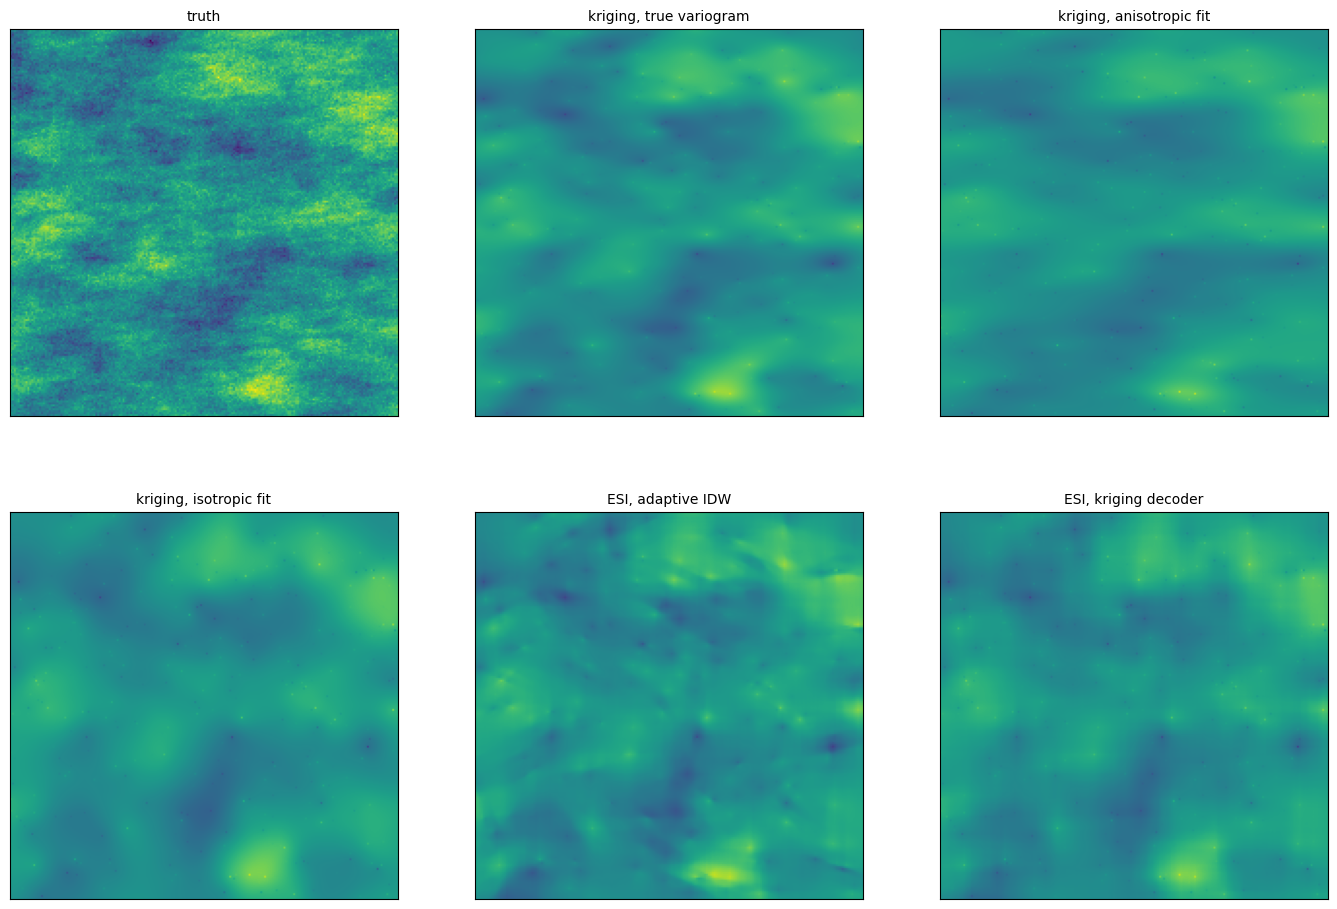

,MAE,degrees from x,coherence
truth,0.000,4.122,0.292
"kriging, true variogram",0.436,2.583,0.535
"kriging, anisotropic fit",0.462,1.387,0.587
"kriging, isotropic fit",0.457,14.923,0.100
"ESI, adaptive IDW",0.453,3.321,0.304
"ESI, kriging decoder",0.454,8.769,0.116


In [3]:
def direction(z):
    gx, gy = sobel(z, axis=1), sobel(z, axis=0)
    jxx, jyy, jxy = (gaussian_filter(a, 2.0).mean() for a in (gx * gx, gy * gy, gx * gy))
    mu = np.linalg.eigvalsh([[jxx, jxy], [jxy, jyy]])
    theta = (np.degrees(0.5 * np.arctan2(2 * jxy, jxx - jyy)) + 90.0) % 180.0
    return min(theta, 180 - theta), (mu[1] - mu[0]) / (mu[1] + mu[0])   # degrees away from the x axis

def isotropic_fit(points, values):
    i, j = np.triu_indices(len(points), 1)
    dist = np.hypot(*(points[i] - points[j]).T)
    half_sq = 0.5 * (values[i] - values[j]) ** 2
    bins = np.digitize(dist, np.linspace(0, 100, 21))
    h = np.array([dist[bins == b].mean() for b in range(1, 21)])
    g = np.array([half_sq[bins == b].mean() for b in range(1, 21)])
    (c0, c, a), _ = curve_fit(lambda h, c0, c, a: c0 + c * spherical(h, a), h, g, p0=[0.1, 0.9, 40],
                              bounds=([0, 0.01, 1], [2, 5, 300]))
    return c0, c, a

def anisotropic_fit(points, values, tolerance=11.25):
    i, j = np.triu_indices(len(points), 1)
    sep = points[j] - points[i]
    dist = np.hypot(sep[:, 0], sep[:, 1])
    azimuth = np.degrees(np.arctan2(sep[:, 1], sep[:, 0])) % 180
    half_sq = 0.5 * (values[i] - values[j]) ** 2
    fits = {}
    for theta in range(0, 180, 15):
        sel = (np.abs((azimuth - theta + 90) % 180 - 90) <= tolerance) & (dist < 100)
        bins = np.digitize(dist[sel], np.linspace(0, 100, 16))
        keep = [b for b in range(1, 16) if (bins == b).sum() > 20]
        h = np.array([dist[sel][bins == b].mean() for b in keep])
        g = np.array([half_sq[sel][bins == b].mean() for b in keep])
        fits[theta], _ = curve_fit(lambda h, c0, c, a: c0 + c * spherical(h, a), h, g, p0=[0.1, 0.9, 40],
                                   bounds=([0, 0.01, 1], [2, 5, 300]))
    major = max(fits, key=lambda t: fits[t][2])
    c0, c, a_major = fits[major]
    return c0, c, a_major, fits[(major + 90) % 180][2], major

def estimates(points, values):
    c0, c, a = isotropic_fit(points, values)
    f0, f1, f_major, f_minor, f_angle = anisotropic_fit(points, values)
    alpha = esi_pareto_hparams_search(points, values, local_interpolator="adaptiveidw", n_partitions=[100],
                                      alpha=[0.8, 0.9, 0.95, 0.98], k="loo", scoring=sc.mae,
                                      seed=0).best_result(strategy="knee")["alpha"]
    true_ok = OrdinaryKriging(points[:, 0], points[:, 1], values, variogram_model="spherical",
                              variogram_parameters={"sill": nugget + partial_sill, "range": range_x, "nugget": nugget},
                              anisotropy_scaling=range_x / range_y, anisotropy_angle=0.0)
    aniso_ok = OrdinaryKriging(points[:, 0], points[:, 1], values, variogram_model="spherical",
                               variogram_parameters={"sill": f0 + f1, "range": f_major, "nugget": f0},
                               anisotropy_scaling=f_major / f_minor, anisotropy_angle=float(f_angle))
    iso_ok = OrdinaryKriging(points[:, 0], points[:, 1], values, variogram_model="spherical",
                             variogram_parameters={"sill": c0 + c, "range": a, "nugget": c0})
    print(f"anisotropic fit, major axis at {f_angle}° with range {f_major:.0f}, minor range {f_minor:.0f}")
    return {"kriging, true variogram": true_ok.execute("points", xi[:, 0], xi[:, 1])[0].data,
            "kriging, anisotropic fit": aniso_ok.execute("points", xi[:, 0], xi[:, 1])[0].data,
            "kriging, isotropic fit": iso_ok.execute("points", xi[:, 0], xi[:, 1])[0].data,
            "ESI, adaptive IDW": esi_nongriddata(points, values, xi, local_interpolator="adaptiveidw", alpha=alpha,
                                                 n_partitions=100, seed=0).estimation(),
            "ESI, kriging decoder": esi_nongriddata(points, values, xi, local_interpolator="kriging", model="spherical",
                                                    nugget=c0, range=a, sill=c0 + c, alpha=alpha, n_partitions=100,
                                                    seed=0).estimation()}

truth = fields[..., 0]
maps = estimates(points, sample_1pct[0]["sim1"].values)
fig, axes = plt.subplots(2, 3, figsize=(17, 11.5))
for ax, (title, z) in zip(axes.ravel(), [("truth", truth.ravel())] + list(maps.items())):
    ax.imshow(z.reshape(200, 200), origin="lower", cmap="viridis", vmin=truth.min(), vmax=truth.max())
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

summary = {"truth": dict(zip(["degrees from x", "coherence"], direction(truth)), MAE=0.0)}
for name, z in maps.items():
    summary[name] = dict(zip(["degrees from x", "coherence"], direction(z.reshape(200, 200))),
                         MAE=np.mean(np.abs(z - truth.ravel())))
pd.DataFrame(summary).T[["MAE", "degrees from x", "coherence"]].round(3)

All five maps keep the field's main patches, smoother than the truth, whose fine detail no estimate
recovers from 400 samples. Kriging with the true variogram has the lowest error. The anisotropic fit
finds the right direction on this realisation but a major range of 98 against the true 72, so its map
draws the patches as long streaks, a coherence of 0.59 against the truth's 0.29, with the largest error
of the five. Kriging with the true variogram also stretches more than the field, at 0.54, since it
smooths along the long direction. The isotropic fit rounds the patches, its direction 15° off and its
coherence 0.10. Adaptive IDW, told nothing, points 3° from the x axis with the truth's coherence, 0.30.
Its map is sharper, with small spots around the data where a cell fits a high exponent. The kriging
decoder sits close to the isotropic kriging.

### Ten realisations

One realisation could favour any method. The same five estimates on the first ten realisations, each
with its own 400 samples at the same locations, give their errors against the truth.

In [4]:
errors = {}
for k in range(10):
    values = sample_1pct[0][realisations[k]].values
    errors[realisations[k]] = {name: np.mean(np.abs(z - fields[..., k].ravel()))
                               for name, z in estimates(points, values).items()}
errors = pd.DataFrame(errors).T
summary_table = pd.DataFrame({"mean MAE": errors.mean(), "best on": errors.idxmin(axis=1).value_counts()}).fillna(0)
summary_table["excess over the true variogram"] = summary_table["mean MAE"] / summary_table.loc["kriging, true variogram", "mean MAE"] - 1
summary_table.round(3)

anisotropic fit, major axis at 0° with range 98, minor range 34
anisotropic fit, major axis at 15° with range 152, minor range 32
anisotropic fit, major axis at 165° with range 92, minor range 38
anisotropic fit, major axis at 45° with range 111, minor range 60
anisotropic fit, major axis at 105° with range 88, minor range 47
anisotropic fit, major axis at 165° with range 111, minor range 42
anisotropic fit, major axis at 75° with range 98, minor range 54
anisotropic fit, major axis at 15° with range 194, minor range 34
anisotropic fit, major axis at 45° with range 80, minor range 28
anisotropic fit, major axis at 45° with range 148, minor range 51


,mean MAE,best on,excess over the true variogram
"ESI, adaptive IDW",0.454,0.0,0.056
"ESI, kriging decoder",0.451,0.0,0.049
"kriging, anisotropic fit",0.470,0.0,0.093
"kriging, isotropic fit",0.447,0.0,0.039
"kriging, true variogram",0.430,10.0,0.000


Kriging with the true variogram is the best on every realisation. The isotropic fit comes 4 % behind it,
the kriging decoder 5 %, adaptive IDW 6 % and the anisotropic fit 9 %, the worst of the five. Modelled
from 400 samples, the anisotropy often goes wrong. The printed fits put the major axis at 45°, 75° or
105° on five realisations whose truth lies at 0°, with a major range anywhere from 80 to 194 against the
true 72. On these data a practitioner who models the anisotropy does worse than one who ignores it. The
ensemble, told nothing, comes 1 % to 2 % behind the isotropic fit, while its map keeps the direction of
the field, at least on the realisation drawn above.

## Pitfalls

- **The kriging decoder expected to see the direction.** Its variogram is isotropic, so any direction
  in its map comes from the data near each location, not from its model.
- **Adaptive IDW's spots read as structure.** The small bright and dark spots around some data come from
  cells whose fit chose a high exponent, not from the field. They mark where a single datum dominates its
  cell.
- **Too few data per cell for a direction.** Adaptive IDW fits a direction in every cell, so a cell with
  a handful of data fits it poorly. At fine granularities the directions turn noisy, which the Pareto
  search weighs against the smaller encoder error.
- **Coherence read as accuracy.** A map can stretch more than the field, as kriging with the true
  variogram does here. Compare a map's coherence with that of the field, when known, or with that of
  other estimates, not with zero.

## Try it yourself

1. Use the denser sample of 2 000 data (`sample_5pct`). The estimates take longer, about two minutes per
   realisation.
2. Give the ESI kriging decoder the true variogram's longer range, and then its shorter one.
3. Read the adaptive IDW's direction cell by cell, on a coarser granularity, and compare it with the x
   axis.

## Next

- *The variogram as an inference*, to read the direction and the ranges from the ensemble.
- *The kriging decoder against global kriging*, for what the local systems approximate.
- *Choosing an ensemble with the Pareto search*, on the same field.
- The documentation's [Decoders](https://spatialize.readthedocs.io/en/latest/theory/decoders.html) (theory).